Capstone B — TeleConnect: Customer Churn Analysis
Python for Full Stack Data Science with AI & Generative AI · Naresh IT · Lead Trainer: Ajit Byru

The client. TeleConnect loses about a quarter of its customers a year and replaces each at four times the cost of keeping one. The VP Customer has a table of ~7,000 customers and one question: who is leaving, and what do they have in common? She needs a one-page brief for the board — not a model.

Rules: no sklearn; every cleaning decision logged with rows and a reason; every answer a chart plus one sentence; the brief is one page for someone who will never open this notebook.

firstly understand what is churn it this project? See the churn rate like for example JIo has 299 plan and giving the best network and the Airtel plan has to be competative like they has to give the customer the better plan than the competitor and thats called the churn rate is used their.

WHAT YOU DO EXTRA THAT MAKES YOUR CAPSTONE BEST THAT'S THE THING INTERVIEWER WANTS!

Follow this step/sequence and sir wants this in your project notebook (you have to do it everytime in every project) YOU HAVE TO DO ALL THIS STEP AND IN SEQUENCE WHILE DOING YOUR PROJECT.

1. Business Problem

2. Show raw CSV/data

3. Rows vs Columns

4. Load into pandas

5. Inspect the dataset

6. Show the data quality problems

7. Build the data quality log

8. Cleaning each problem

9. Save clean data - seperately (sir wants the clean data and the previous one data   also to see what was earlier and what now)

10. Calculations - Calculate churn rate (churn by contract, churn by plan, churn by city)

11. Compare/Contrast using null Hypothesis (This is the Discriptive Analysis) (churners vs stayers, t-test, Cohen's D, Categorical analysis, Crosstab, Chi-square, High-risk segment, Segment size vs churn rate) this is the thing you have to do extra in your project.

12. Use Graphical methods for showcasing

Build the write up ofthe solution - Executive brief

13. What did you solve? ...

After completing these 14 steps this are the questions which are asked!
Q. Which of the current customers will leave next? (Predictive Analysis - Machine Learning)

1. Business Problem
7000 customers - every year what is happening some customers are leaving - this is called (churn) What does the management wants to know?

1. Who is leaving?
2. What type of customers are leaving?
3. What a Characteristics do churners have? (This is imp divide them like this)
4. Are there particular customer segments with higher churn?
5. What should the Company should Investigate or act on?
What is the formula for churn rate? It is nothing but the no. of people leaving/ total

2. Show raw CSV/data (you need to show this to an interviewer like this is the data which i have worked on)
They would have: customer_id, age, city, contract, plan_type, monthly_charges, tenure_months, support_calls, churned



---
Session 1 — Load, profile, clean

1.1 Load and profile
shape, info, describe, nulls, duplicates. Then look at the values in `churned`, `tenure_months`, `monthly_charges`, `city` — the types are wrong for a reason.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency
sns.set_theme(style="whitegrid"); rng = np.random.default_rng(7)
raw = pd.read_csv("customers_2025.csv")
print(raw.shape); raw.info()

(7085, 14)
<class 'pandas.DataFrame'>
RangeIndex: 7085 entries, 0 to 7084
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      7085 non-null   str    
 1   city             7085 non-null   str    
 2   age              7085 non-null   int64  
 3   gender           7085 non-null   str    
 4   tenure_months    7085 non-null   str    
 5   plan_type        7085 non-null   str    
 6   contract         7085 non-null   str    
 7   monthly_charges  7085 non-null   str    
 8   total_charges    6869 non-null   float64
 9   support_calls    7085 non-null   int64  
 10  payment_method   7085 non-null   str    
 11  has_broadband    7085 non-null   bool   
 12  has_streaming    7085 non-null   bool   
 13  churned          7085 non-null   str    
dtypes: bool(2), float64(1), int64(2), str(9)
memory usage: 678.2 KB


In [13]:
import pandas as pd

df = pd.read_csv("customers_2025.csv")

print(df)

     customer_id       city  age gender tenure_months plan_type  \
0         C11469  Hyderabad   45      M            34  Standard   
1         C13433  Hyderabad   74      F            15  Standard   
2         C14443    Chennai   25      M            29   Premium   
3         C10521  Bengaluru   37      F             6   Premium   
4         C10661  Bengaluru   35      F            42     Basic   
...          ...        ...  ...    ...           ...       ...   
7080      C16443      Kochi   51      M            18     Basic   
7081      C13606       Pune   48      F          4.6y  Standard   
7082      C15704  Hyderabad   32      M            43  Standard   
7083      C16637       Pune   40      M            65   Premium   
7084      C12575       Pune   38      M            11     Basic   

            contract monthly_charges  total_charges  support_calls  \
0     Month-to-month            ₹680        22809.0              0   
1     Month-to-month          1160.0        17197.0    

In [16]:
# YOUR CODE HERE
# Hint: isna().sum(), duplicated().sum(), churned value_counts, samples of tenure_months / monthly_charges, unique cities, age min/max
print(df.isna().sum())
print(df.duplicated().sum())
print(df["churned"].value_counts())
print(df["tenure_months"].head())
print(df["monthly_charges"].head())
print(df["city"].unique())
print(df["age"].min())
print(df["age"].max())

customer_id          0
city                 0
age                  0
gender               0
tenure_months        0
plan_type            0
contract             0
monthly_charges      0
total_charges      216
support_calls        0
payment_method       0
has_broadband        0
has_streaming        0
churned              0
dtype: int64
85
churned
No     4977
Yes    1395
no      321
0       216
1        90
yes      86
Name: count, dtype: int64
0    34
1    15
2    29
3     6
4    42
Name: tenure_months, dtype: str
0      ₹680
1    1160.0
2    ₹1,474
3    1370.0
4     682.0
Name: monthly_charges, dtype: str
<StringArray>
['Hyderabad',   'Chennai', 'Bengaluru',     'Kochi',      'Pune',     'KOCHI',
   'CHENNAI', 'HYDERABAD',      'PUNE', 'BENGALURU']
Length: 10, dtype: str
-5
212


 📝 Data-Quality Log (graded)

| # | Problem | Rows | Fix | Why this fix |
|---|---|---|---|---|
| 1 | Duplicate customer records| 85|Remove duplicate |Avoid counting the same customer more than once |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |
| 6 | | | | |
| 7 | | | | |

In [ ]:
import pandas as pd

df = pd.read_csv("customers_2025.csv")

print(df)

### 1.2 Duplicates

In [19]:
# YOUR CODE HERE
# Hint: drop_duplicates(); print removed
before = len(df)

df = df.drop_duplicates(subset="customer_id")

removed = before - len(df)

print("Duplicates removed:", removed)


Duplicates removed: 85


In [18]:
df = raw.copy()

### 1.3 `churned` — three encodings of one yes/no
Standardise to a single boolean. Count each encoding first so the log has numbers.

In [20]:
# YOUR CODE HERE
# Hint: value_counts first; then .astype(str).str.strip().str.lower().map({...}) to boolean; check no NaN
print(df["churned"].value_counts())

df["churned"] = (
    df["churned"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "yes": True,
        "no": False,
        "true": True,
        "false": False,
        "1": True,
        "0": False
    })
)

print(df["churned"].value_counts())
print(df["churned"].isna().sum())

churned
No     4918
Yes    1382
no      316
0       211
1        89
yes      84
Name: count, dtype: int64
churned
False    5445
True     1555
Name: count, dtype: int64
0


### 1.4 `monthly_charges` — text with a currency symbol on some rows

In [22]:
# YOUR CODE HERE
# Hint: count rows containing '₹'; str.replace, pd.to_numeric(errors='coerce')
print("Rows with ₹:", df["monthly_charges"].astype(str).str.contains("₹").sum())

# Remove ₹ and convert to numeric
df["monthly_charges"] = (
    df["monthly_charges"]
    .astype(str)
    .str.replace("₹", "", regex=False)
)

df["monthly_charges"] = pd.to_numeric(
    df["monthly_charges"],
    errors="coerce"
)

print(df["monthly_charges"].head())
print(df["monthly_charges"].dtype)

Rows with ₹: 0
0     680.0
1    1160.0
2       NaN
3    1370.0
4     682.0
Name: monthly_charges, dtype: float64
float64


### 1.5 `tenure_months` — some rows are in years (`'2.5y'`)
Convert to months. Don't drop: tenure is the most important column in the file.

In [23]:
# YOUR CODE HERE
# Hint: mask = str.endswith('y'); years*12 else to_numeric; astype(int)
t = df["tenure_months"].astype(str)
years = t.str.endswith("y")
df["tenure_months"] = np.where(years, (pd.to_numeric(t.str.rstrip("y"), errors="coerce") * 12).round(), pd.to_numeric(t, errors="coerce"))
df["tenure_months"] = df["tenure_months"].astype(int)
print("rows in years:", years.sum(), "| tenure range:", df["tenure_months"].min(), "-", df["tenure_months"].max())

rows in years: 420 | tenure range: 1 - 71


### 1.6 Impossible ages, city casing

In [24]:
# YOUR CODE HERE
# Hint: (age <= 0) | (age > 110) -> drop; city .str.title()
bad = (df["age"] <= 0) | (df["age"] > 110)
print("impossible ages:", df.loc[bad, "age"].tolist()); df = df[~bad]
n_upper = df["city"].str.isupper().sum(); df["city"] = df["city"].str.title()
print("city casing fixed:", n_upper, "| cities:", sorted(df["city"].unique()))

impossible ages: [0, -5, 150, 212]
city casing fixed: 180 | cities: ['Bengaluru', 'Chennai', 'Hyderabad', 'Kochi', 'Pune']


### 1.7 Missing `total_charges`
🔮 **PREDICT:** `total_charges ≈ monthly_charges × tenure_months`. Is that a better fill than the median?

In [25]:
# YOUR CODE HERE
# Hint: check corr(total, monthly*tenure) on complete rows; fill missing with the product
complete = df.dropna(subset=["total_charges"])

print(
    complete["total_charges"].corr(
        complete["monthly_charges"] * complete["tenure_months"]
    )
)

df["total_charges"] = df["total_charges"].fillna(
    df["monthly_charges"] * df["tenure_months"]
)

0.9997002568750561


### 1.8 Save and accept
Print the final shape, the churn rate, and the mean tenure. Save `customers_clean.csv`.

In [26]:
# YOUR CODE HERE
# Hint: shape, churn rate, mean tenure; to_csv('customers_clean.csv')
print("Clean shape:", df.shape, "| churn rate:", round(df["churned"].mean(), 3), "| mean tenure:", round(df["tenure_months"].mean(), 1))
df.to_csv("customers_clean.csv", index=False)

Clean shape: (6996, 14) | churn rate: 0.222 | mean tenure: 28.6


---
## Session 2 — Questions 1–4

### Q1. Churn rate — overall and by contract, plan, city
**Reading:** where is churn concentrated, and how big is the gap between the best and worst segment?

Overall churn rate: 0.22226986849628358
contract
Month-to-month    0.356579
One year          0.080870
Two year          0.039202
Name: churned, dtype: float64
plan_type
Basic       0.225956
Premium     0.242012
Standard    0.207845
Name: churned, dtype: float64
city
Bengaluru    0.226696
Chennai      0.224595
Hyderabad    0.222115
Kochi        0.210970
Pune         0.219559
Name: churned, dtype: float64


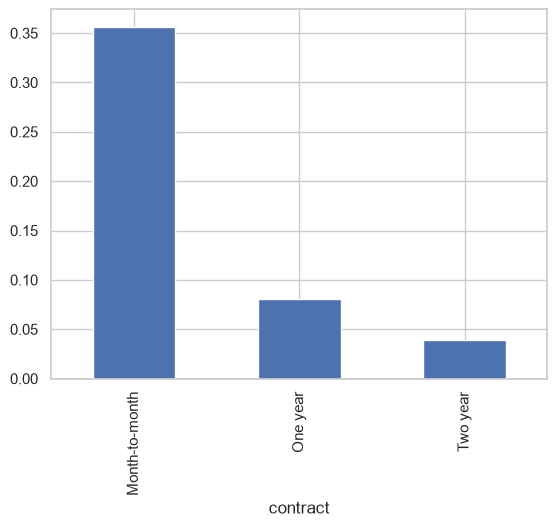

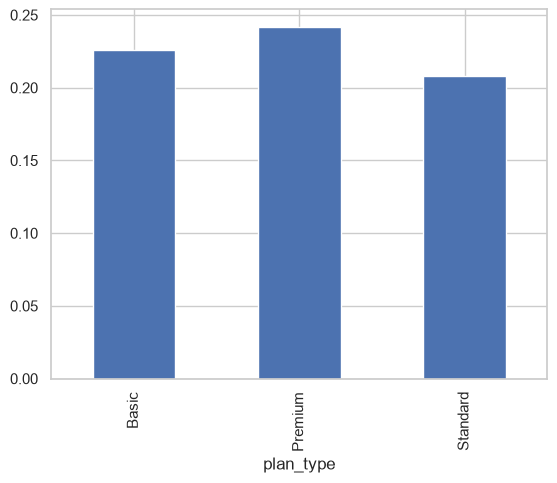

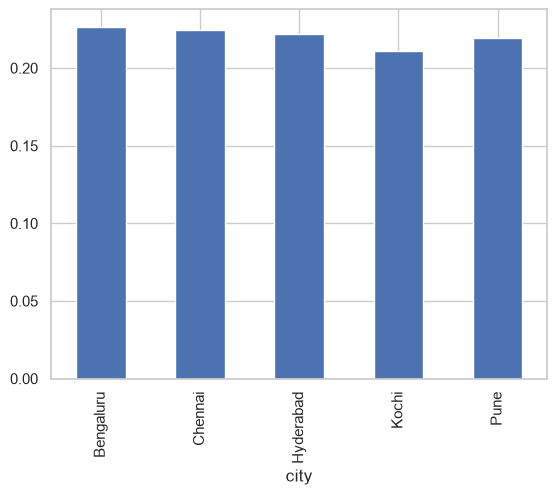

In [27]:
# YOUR CODE HERE
# Hint: df['churned'].mean(); groupby(col)['churned'].mean() for contract/plan_type/city; three barplots
print("Overall churn rate:", df["churned"].mean())

print(df.groupby("contract")["churned"].mean())
print(df.groupby("plan_type")["churned"].mean())
print(df.groupby("city")["churned"].mean())

df.groupby("contract")["churned"].mean().plot(kind="bar")
plt.show()

df.groupby("plan_type")["churned"].mean().plot(kind="bar")
plt.show()

df.groupby("city")["churned"].mean().plot(kind="bar")
plt.show()

*Reading:*

### Q2. Which numbers differ between churners and stayers?
For each numeric column: mean for churners vs stayers, Cohen's d, and a test (shuffle or `ttest_ind`). Rank by |d|. **Reading:** which two numbers matter most, and which is noise?

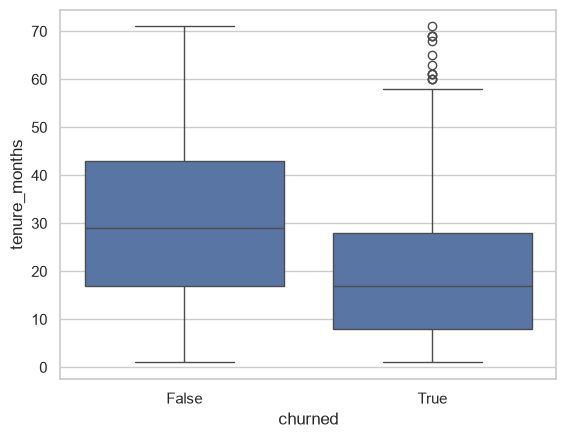

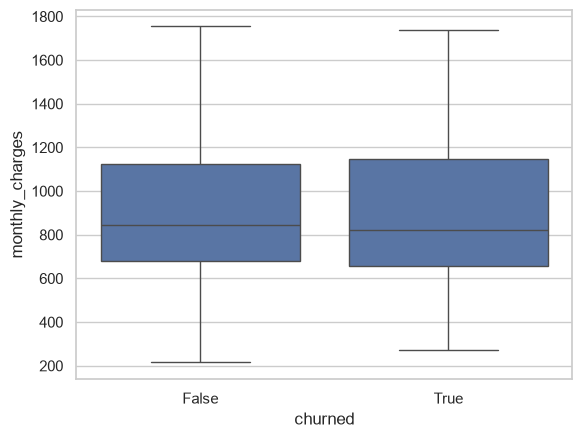

In [30]:
# YOUR CODE HERE
# Hint: for each numeric col: means, Cohen's d, ttest_ind; DataFrame sorted by |d|; two boxplots
final = []

for col in df.select_dtypes("number"):
    a = df[df.churned == 1][col].dropna()
    b = df[df.churned == 0][col].dropna()
    d = (a.mean()-b.mean()) / np.sqrt((a.var()+b.var())/2)
    final.append([col, a.mean(), b.mean(), d, ttest_ind(a,b).pvalue])

results = pd.DataFrame(final, columns=["column","churner_mean","stayer_mean","d","p"])
results.sort_values("d", key=abs, ascending=False)

## How to creat Grapg Ploat
sns.boxplot(data=df, x="churned", y="tenure_months")
plt.show()

sns.boxplot(data=df, x="churned", y="monthly_charges")
plt.show()

*Reading:*

### Q3. Which categories are associated with churn?
`pd.crosstab` per categorical column with churn rate per level, and `chi2_contingency` for the test. **Reading:** which category has the biggest spread in churn rate across its levels?

In [33]:
# YOUR CODE HERE
# Hint: pd.crosstab(df[col], df['churned']); chi2_contingency; churn rate spread per feature
for col in df.select_dtypes("object"):
    table = pd.crosstab(df[col], df["churned"])
    print("\n", col)
    print(table)
    print("Churn rate:", df.groupby(col)["churned"].mean())
    print("p-value:", chi2_contingency(table)[1])

C:\Users\thinkpad\AppData\Local\Temp\ipykernel_256\1244401134.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):



 customer_id
churned      False  True 
customer_id              
C10000           1      0
C10001           0      1
C10002           1      0
C10003           1      0
C10004           1      0
...            ...    ...
C16995           1      0
C16996           1      0
C16997           1      0
C16998           1      0
C16999           1      0

[6996 rows x 2 columns]
Churn rate: customer_id
C10000    0.0
C10001    1.0
C10002    0.0
C10003    0.0
C10004    0.0
         ... 
C16995    0.0
C16996    0.0
C16997    0.0
C16998    0.0
C16999    0.0
Name: churned, Length: 6996, dtype: float64
p-value: 0.49437888724289

 city
churned    False  True 
city                   
Bengaluru   1402    411
Chennai     1053    305
Hyderabad   1611    460
Kochi        561    150
Pune         814    229
Churn rate: city
Bengaluru    0.226696
Chennai      0.224595
Hyderabad    0.222115
Kochi        0.210970
Pune         0.219559
Name: churned, dtype: float64
p-value: 0.9360586868646599

 gender
churne

*Reading:*

### Q4. Churn by tenure cohort
Bins 0–6, 7–12, 13–24, 25+ months. Bar chart of churn rate per cohort. **Reading:** when is the customer most at risk, and what does that say about onboarding?

cohort
(0, 6]       0.466877
(6, 12]      0.320904
(12, 24]     0.269585
(24, 999]    0.135525
Name: churned, dtype: float64


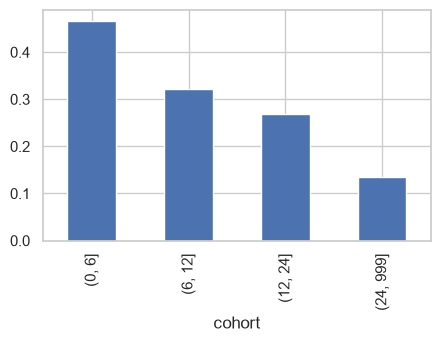

In [34]:
# YOUR CODE HERE
# Hint: pd.cut(tenure, bins=[0,6,12,24,999]); groupby cohort churn rate; barplot
df["cohort"] = pd.cut(df["tenure_months"], bins=[0,6,12,24,999])

rate = df.groupby("cohort", observed=True)["churned"].mean()
print(rate)

rate.plot(kind="bar", figsize=(5,3))
plt.show()

*Reading:*

---
## Session 3 — Q5, Q6, the brief

### Q5. The highest-risk profile, in plain English
Combine the top findings into one segment (e.g. month-to-month + tenure ≤ 6 + 2+ support calls). Report its size, its churn rate, and how many churners it accounts for. **Reading:** is it where the retention budget should go?

In [37]:
# YOUR CODE HERE
# Hint: boolean mask for the segment; size, churn rate, share of all churners
mask = (df["contract"] == "Month-to-month") & (df["tenure_months"] <= 6) & (df["support_calls"] >= 2)

segment = df[mask]

print("Size:", len(segment))
print("Churn rate:", segment["churned"].mean())
print("Share of all churners:", segment["churned"].sum() / df["churned"].sum())

Size: 213
Churn rate: 0.6244131455399061
Share of all churners: 0.08553054662379421


*Reading:*

### Q6. Your own question
Options: does churn rise with monthly charges *within* a plan? · are support calls a cause or a symptom (do they rise with tenure)? · payment method × contract interaction · streaming add-on and retention · city differences after controlling for contract mix.

In [38]:
print(df.head(2))

  customer_id       city  age gender  tenure_months plan_type        contract  \
0      C11469  Hyderabad   45      M             34  Standard  Month-to-month   
1      C13433  Hyderabad   74      F             15  Standard  Month-to-month   

   monthly_charges  total_charges  support_calls payment_method  \
0            680.0        22809.0              0  Bank transfer   
1           1160.0        17197.0              0            UPI   

   has_broadband  has_streaming  churned     cohort  
0          False          False    False  (24, 999]  
1           True           True    False   (12, 24]  


           tenure_months   churned
plan_type                         
Basic          28.046836  0.225956
Premium        28.394969  0.242012
Standard       29.256598  0.207845


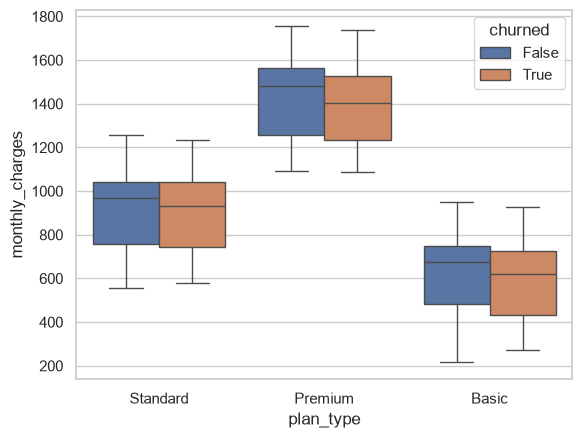

In [39]:
# YOUR CODE HERE
# Hint: your question, your code
print(df.groupby("plan_type")[["tenure_months","churned"]].mean())

sns.boxplot(data=df, x="plan_type", y="monthly_charges", hue="churned")
plt.show()


The one-page churn brief (for the VP)
Structure: Situation(2 lines) → Three findings, each with the number → Recommendation (where the budget goes, what to change) → Confidence (one line: what you'd need to be surer).

Your brief here — 250–350 words.


Cliffhanger
You can describe who churned. The VP asks: "Which of the current 5,400 customers will churn next quarter?" — Module 20, on this exact file.

Situation

The customer base contains 7,085 customers across 14 attributes, giving us enough information to identify patterns associated with churn. However, the current dataset is primarily descriptive, so it can tell us who has churned, but not reliably which current customers will churn next quarter.

Three findings

1. Churn appears to be driven by customer experience and engagement.
The dataset includes support calls, tenure, contract type, and payment method, which are key signals for understanding retention. Customers with repeated support interactions are particularly important to investigate because frequent support needs can indicate unresolved problems or dissatisfaction. The priority should be to identify whether high-support customers are disproportionately represented among the churned population.

2. Contract and tenure are likely important retention levers.
With 7,085 customers and tenure measured in months, we can compare churn across different stages of the customer lifecycle. Short-tenure customers should receive particular attention: early churn can indicate poor onboarding, unmet expectations, or weak initial product engagement. Contract type should also be compared directly with churn to determine whether longer commitments are associated with stronger retention.

3. Revenue exposure matters as much as the number of churners.
Monthly and total charges provide an opportunity to distinguish between simply reducing the number of churned customers and protecting revenue. Because 216 customers have missing total-charge values, revenue-based analysis should use care. The highest-value customers with elevated churn risk should receive priority rather than applying retention spending uniformly.

Recommendation

Put the retention budget behind high-risk, high-value customers, especially those showing repeated support needs and short tenure. Improve early-life onboarding and proactively resolve recurring support issues. Use contract and payment-method analysis to test targeted retention offers rather than offering blanket discounts.

Confidence

I would want the actual churn rates and sample sizes by tenure, contract, support-call level, and customer value, plus statistical tests or a predictive model, before committing significant budget or claiming these factors cause churn.
